#### Flaky Test Prediction: Data Exploration and Feasibility

KA1 Milestone 1 notebook.

**Data:** FlakeFlagger dataset (Alshammari et al., 2021), public on GitHub, both files are read from the authors' repository.

**Contents:** target and class balance, projects, features, missing values, test code words, leakage checks, fold design, and baseline checks.

#### Setup

In [1]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

pd.set_option("display.width", 120)

#### Load the data

In [2]:
BASE = "https://raw.githubusercontent.com/AlshammariA/FlakeFlagger/main/flakiness-predicter/result/"
df = pd.read_csv(BASE + "processed_data.csv")
vocab = pd.read_csv(BASE + "processed_data_with_vocabulary_per_test.csv", usecols=["test_name", "tokenList"])

id_cols = ["Unnamed: 0", "test_name", "project", "testClassName", "testMethodName", "flaky"]
all_features = [c for c in df.columns if c not in id_cols]

print("Tests:   ", len(df))
print("Projects:", df["project"].nunique())
print("Features:", len(all_features))

Tests:    22236
Projects: 24
Features: 23


#### Target: flaky or not flaky

One row is one test method. _flaky_ is 1 if the test both passed and failed when the authors reran each project's test suite 10,000 times.

In [3]:
print(df["flaky"].value_counts())
print(f"Flaky share: {df['flaky'].mean():.2%}")
print(f"Accuracy if every test is called 'not flaky': {1 - df['flaky'].mean():.2%} (finds no flaky tests)")

flaky
0    21425
1      811
Name: count, dtype: int64
Flaky share: 3.65%
Accuracy if every test is called 'not flaky': 96.35% (finds no flaky tests)


Accuracy is not useful here. The main score is PR-AUC, which focuses on the rare flaky class. A model that ranks tests at random scores about the flaky share, 0.036.

#### Projects

In [4]:
by_project = (df.groupby("project")["flaky"]
                .agg(tests="size", flaky="sum", flaky_rate="mean")
                .sort_values("flaky", ascending=False)
                .round(3))
by_project

,tests,flaky,flaky_rate
project,,,
spring-boot,2127,163,0.077
hbase,431,145,0.336
alluxio,187,116,0.620
okhttp,810,100,0.123
ambari,324,52,0.160
hector,142,33,0.232
activiti,2044,32,0.016
java-websocket,145,23,0.159
wildfly,1236,23,0.019


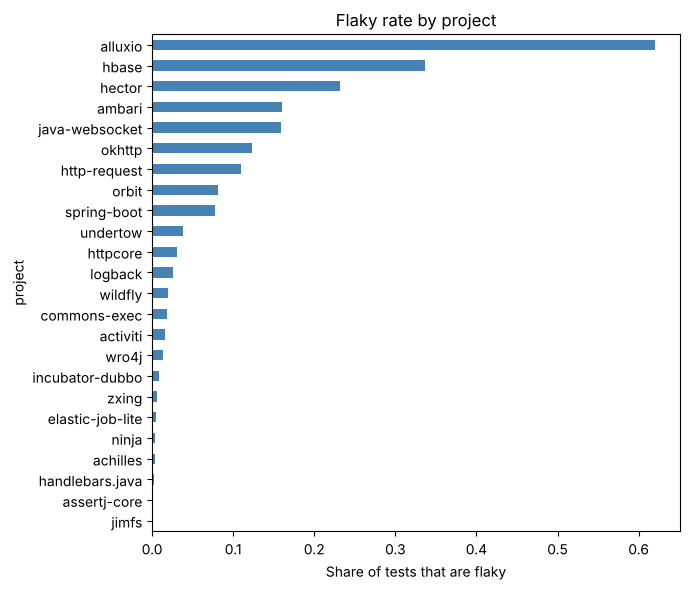

In [5]:
ax = by_project["flaky_rate"].sort_values().plot.barh(figsize=(7, 6), color="steelblue")
ax.set_xlabel("Share of tests that are flaky")
ax.set_title("Flaky rate by project")
plt.tight_layout()
plt.show()

In [6]:
top4 = by_project["flaky"].head(4).sum() / by_project["flaky"].sum()
print(f"Top 4 projects hold {top4:.0%} of all flaky tests")
print("Projects with no flaky tests:", (by_project["flaky"] == 0).sum())

Top 4 projects hold 65% of all flaky tests
Projects with no flaky tests: 1


Flaky rates go from 0% to 62% by project, and four projects hold most of the flaky tests. Tests from the same project share code and setup, so the project, not the test, is the unit for splitting.

#### Features

The original table has 23 features, including eight overlapping code-change windows (5 to 10,000 commits). Only the 100-commit window is kept, which leaves 16: eight yes/no flags for risky test patterns (test smells), test size and coverage, run time, project coverage, code changes in the last 100 commits, and third-party libraries.

In [7]:
smells = ["assertion-roulette", "conditional-test-logic", "eager-test", "fire-and-forget",
          "indirect-testing", "mystery-guest", "resource-optimism", "test-run-war"]
measures = ["testLength", "numAsserts", "numCoveredLines", "ExecutionTime",
            "projectSourceLinesCovered", "projectSourceClassesCovered",
            "hIndexModificationsPerCoveredLine_window100", "num_third_party_libs"]
features = smells + measures

df[measures].describe().T[["mean", "50%", "max"]].round(2)

,mean,50%,max
testLength,12.27,8.00,765.00
numAsserts,1.88,1.00,575.00
numCoveredLines,13.81,6.00,765.00
ExecutionTime,0.97,0.04,1515.48
projectSourceLinesCovered,88.78,26.00,2873.00
projectSourceClassesCovered,33.39,13.00,377.00
hIndexModificationsPerCoveredLine_window100,1.01,1.00,17.00
num_third_party_libs,2.18,0.00,161.00


#### Missing values

In [8]:
missing = df[features].isna().sum()
print(missing[missing > 0])
print("Tests with any missing value:", df[features].isna().any(axis=1).sum())

testLength         273
numAsserts         273
numCoveredLines    273
dtype: int64
Tests with any missing value: 273


The same 273 tests miss size, assert count, and covered lines. They are filled with the median, learned from the training projects only (inside the pipeline).

#### Run time is not comparable across projects

In [9]:
median_time = df.groupby("project")["ExecutionTime"].median().sort_values()
print(f"Lowest project median:  {median_time.iloc[0]:.3f} ({median_time.index[0]})")
print(f"Highest project median: {median_time.iloc[-1]:.3f} ({median_time.index[-1]})")
print(f"About {median_time.iloc[-1] / median_time.iloc[0]:.0f} times apart")

Lowest project median:  0.002 (incubator-dubbo)
Highest project median: 1.105 (ambari)
About 552 times apart


A test that is slow in one project can be normal in another. So each measure also gets a project-relative version: its percentile among the tests of its own project.

In [10]:
for col in measures:
    df["rel_" + col] = df.groupby("project")[col].rank(pct=True)

df[["project", "ExecutionTime", "rel_ExecutionTime"]].sample(5, random_state=1)

,project,ExecutionTime,rel_ExecutionTime
16210,assertj-core,2.090,0.969334
2483,okhttp,0.023,0.440741
2401,okhttp,0.008,0.243210
4523,elastic-job-lite,0.006,0.329749
1090,handlebars.java,2.833,0.960187


#### Test code words

The second file lists the words in each test's source code (Pinto et al., 2020). It is matched to the main file by test name.

In [11]:
vocab["key"] = vocab["test_name"].str.lower()
df["key"] = df["test_name"].str.lower()
df = df.merge(vocab[["key", "tokenList"]].drop_duplicates("key"), on="key", how="left")
df["words"] = df["tokenList"].fillna("[]").apply(ast.literal_eval)

print(f"Tests with code words: {df['tokenList'].notna().mean():.1%}")
print("Tests without code words:", df["tokenList"].isna().sum())
print("Median words per test:", int(df["words"].str.len().median()))

Tests with code words: 98.7%
Tests without code words: 290
Median words per test: 29


In [12]:
w = df[["project", "flaky"]].assign(word=df["words"].apply(set)).explode("word").dropna()
word_stats = w.groupby("word").agg(tests=("flaky", "size"), flaky=("flaky", "sum"), projects=("project", "nunique"))
word_stats = word_stats[word_stats["flaky"] >= 30]
word_stats["flaky_share"] = (word_stats["flaky"] / word_stats["tests"]).round(3)
word_stats.sort_values("flaky_share", ascending=False).head(10)

,tests,flaky,projects,flaky_share
word,,,,
commonsloggingisnotatransitivedependency,39,39,1,1.0
checkspring,39,39,1,1.0
createbytefile,40,40,1,1.0
checkcommonslogging,39,39,1,1.0
filealreadyexistexception,31,31,1,1.0
fileid,51,51,1,1.0
runbuildfortask,78,78,1,1.0
writetype,46,46,1,1.0
tfs,79,79,1,1.0


Some words that appear often in flaky tests are names from a single project. They would not help on a new project, which is one more reason to hold out whole projects.

#### Leakage checks

In [13]:
dupes = df.duplicated(subset=features, keep=False)
groups = df[dupes].groupby(features, dropna=False)["project"].nunique()
print(f"Tests that share all 16 feature values with another test: {dupes.mean():.1%}")
print(f"Duplicate groups: {len(groups)}, groups that span more than one project: {(groups > 1).sum()}")

Tests that share all 16 feature values with another test: 7.8%
Duplicate groups: 687, groups that span more than one project: 32


- About 8% of tests have a near-copy, and almost all copies sit in the same project (655 of 687 groups). A random split would put them on both sides, so folds are grouped instead.
- Filling and scaling are fitted on training folds only, inside the pipeline.
- The code-change window (100 commits) was chosen in advance, not picked using test folds.
- No feature is built from the flaky label.

#### Fold design

- **Unseen projects:** whole projects are held out, so the model is tested on projects it has never seen.
- **Seen projects:** whole test classes are held out, so the model has seen the project but not those tests.

In [14]:
X = df[features]
y = df["flaky"]
projects = df["project"]
test_classes = df["project"] + "::" + df["testClassName"]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
unseen_folds = list(sgkf.split(X, y, groups=projects))
seen_folds = list(sgkf.split(X, y, groups=test_classes))

for name, folds in [("Unseen projects", unseen_folds), ("Seen projects", seen_folds)]:
    print(name)
    for i, (tr, te) in enumerate(folds, start=1):
        print(f"  fold {i}: {projects.iloc[te].nunique():2d} projects, {len(te):5d} tests, flaky rate {y.iloc[te].mean():.3f}")

Unseen projects
  fold 1:  3 projects,  7258 tests, flaky rate 0.030
  fold 2:  5 projects,  3830 tests, flaky rate 0.033
  fold 3:  4 projects,  3927 tests, flaky rate 0.049
  fold 4:  4 projects,  3324 tests, flaky rate 0.050
  fold 5:  8 projects,  3897 tests, flaky rate 0.027
Seen projects
  fold 1: 22 projects,  4445 tests, flaky rate 0.036
  fold 2: 23 projects,  4446 tests, flaky rate 0.036
  fold 3: 23 projects,  4446 tests, flaky rate 0.036
  fold 4: 24 projects,  4451 tests, flaky rate 0.037
  fold 5: 22 projects,  4448 tests, flaky rate 0.036


#### Does the split matter?

The baseline model, logistic regression with balanced class weights, is scored two ways on all 23 original features: one random 80/20 split, and the project folds above. This tests the evaluation design, not the models.

In [15]:
lr = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                   LogisticRegression(class_weight="balanced", max_iter=2000))

# random split, same seed as the first baseline
X_tr, X_te, y_tr, y_te = train_test_split(df[all_features], y, test_size=0.2, stratify=y, random_state=42)
random_split = average_precision_score(y_te, lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1])

grouped = []
for tr, te in unseen_folds:
    lr.fit(df[all_features].iloc[tr], y.iloc[tr])
    grouped.append(average_precision_score(y.iloc[te], lr.predict_proba(df[all_features].iloc[te])[:, 1]))

print(f"Random 80/20 split:      PR-AUC {random_split:.3f}")
print(f"Whole projects held out: PR-AUC {np.mean(grouped):.3f} (range {min(grouped):.3f} to {max(grouped):.3f})")

Random 80/20 split:      PR-AUC 0.197
Whole projects held out: PR-AUC 0.085 (range 0.045 to 0.151)


Holding out whole projects cuts PR-AUC by more than half. A random split mixes tests from the same project into training and testing, so it overstates how well a model works on a new project.

#### Baselines on held-out projects

Two baselines that need no training: random ranking, and the simple rule "rerun the slowest tests first". Each fold's flaky rate is shown next to its scores, since PR-AUC for random ranking moves with it.

In [16]:
rows = []
for fold, (tr, te) in enumerate(unseen_folds, start=1):
    y_test = y.iloc[te]
    rows.append({"fold": fold,
                 "flaky_rate": y_test.mean(),
                 "random": average_precision_score(y_test, np.random.RandomState(fold).rand(len(te))),
                 "slowest_first": average_precision_score(y_test, X["ExecutionTime"].iloc[te])})

baselines = pd.DataFrame(rows).set_index("fold").round(3)
baselines

,flaky_rate,random,slowest_first
fold,,,
1,0.030,0.037,0.064
2,0.033,0.036,0.129
3,0.049,0.052,0.272
4,0.050,0.055,0.310
5,0.027,0.025,0.065


In [17]:
baselines.mean().round(3)

flaky_rate       0.038
random           0.041
slowest_first    0.168
dtype: float64

- Random ranking scores close to each fold's flaky rate, as expected.
- The slowest-first rule needs no training and is far above random on new projects.
- Scores move a lot between folds, so averages alone are not enough.

#### Feasibility

- Both files load from the public repository, and 98.7% of tests have code words.
- Folds are fixed with a seed, so every result can be reproduced.